# 03 — Decision Tree vs Linear Regression (Supporting Exercise)

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

## 1. Goal

The goal is to compare a simple **Decision Tree** regression model with the previous **Linear Regression** baseline
(`02_linear_regression_review.ipynb`).

Linear Regression was better than predicting the mean, but still weak (R² = 0.26), and it predicted a few impossible
negative durations. Can a Decision Tree capture non-linear relationships in the same data better?

- **Target:** `duration_days`, the recorded activity span (same as before)
- **Features:** `events_per_case`, `unique_activities`, `unique_resources` (same as before)

Using the same features and the same train/test split makes the comparison easier and fairer.

## 2. Load and Prepare Data

Same data and same completed-case logic as the previous notebooks.

In [1]:
import os
import warnings
from pathlib import Path

os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "false"  # no progress bar while loading
# hide only PM4Py's optional speed-up tip ("Install the optional requirement `r4pm` ..."); other warnings still show
warnings.filterwarnings("ignore", message="Install the optional requirement `r4pm`")

import matplotlib.pyplot as plt
import pandas as pd
import pm4py
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

# the project folder: works whether Jupyter starts in the notebooks folder or in the project folder
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = project_root / "data" / "raw" / "BPIC15_1.xes"



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




*When PM4Py is imported it prints a short welcome and licence message. This is normal and not an error.*

In [2]:
log = pm4py.read_xes(str(data_path))
df = pm4py.convert_to_dataframe(log)

case_data = df.groupby("case:concept:name").agg(
    events_per_case=("concept:name", "size"),
    unique_activities=("concept:name", "nunique"),
    unique_resources=("org:resource", "nunique"),
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
)
case_data["duration_days"] = (case_data["last_event"] - case_data["first_event"]).dt.total_seconds() / (24 * 60 * 60)

case_data = case_data[case_data["end_date"].notna()]   # completed cases only
case_data = case_data.reset_index().rename(columns={"case:concept:name": "case_id"})
case_data = case_data[["case_id", "events_per_case", "unique_activities", "unique_resources", "duration_days"]]

print("Completed cases:", len(case_data))
case_data.head()

Completed cases: 956


,case_id,events_per_case,unique_activities,unique_resources,duration_days
0,10009138,45,45,3,55.0
1,10051383,57,56,3,70.0
2,10053042,57,56,3,80.0
3,10093171,46,46,3,79.0
4,10186644,55,54,4,56.0


> **Supporting experiment.** These features describe the **whole finished case**, so they are only known after the
> case ends. This is a regression learning exercise, **not** an early-warning model.

## 3. Features and Target

In [3]:
X = case_data[
    [
        "events_per_case",
        "unique_activities",
        "unique_resources"
    ]
]

y = case_data["duration_days"]

## 4. Same Train/Test Split

Exactly the same split as in the Linear Regression notebook (`test_size=0.20`, `random_state=42`), so both models are
tested on the same 192 cases.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training cases:", len(X_train))
print("Test cases:", len(X_test))

Training cases: 764
Test cases: 192


## 5. Decision Tree Model

A Decision Tree makes predictions by repeatedly **splitting the data into groups** based on feature values.
For example, it may learn rules such as: cases with fewer events go one direction, cases with more events go another
direction. At the end of the tree, each group receives a predicted duration (the average duration of the training cases
in that group).

I use `max_depth=4` only to keep the tree reasonably simple and reduce obvious overfitting.

In [5]:
model = DecisionTreeRegressor(
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

## 6. Evaluate with the Same Metrics

Same definitions as in the Linear Regression notebook:

- **MAE:** on average, how many days the predictions are away from the real values.
- **RMSE:** similar to MAE, but larger mistakes are penalised more.
- **R²:** how much of the variation in the recorded activity span is explained by the model.

In [6]:
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print(f"Decision Tree MAE: {mae:.2f} days")
print(f"Decision Tree RMSE: {rmse:.2f} days")
print(f"Decision Tree R²: {r2:.2f}")

Decision Tree MAE: 58.73 days
Decision Tree RMSE: 125.50 days
Decision Tree R²: 0.27


## 7. Check for Negative Predictions

Linear Regression predicted a few negative durations, which is impossible. A Decision Tree predicts the average duration
of a group of training cases, so its predictions cannot be lower than the shortest training duration.

In [7]:
print(f"Minimum predicted duration: {y_pred.min():.2f} days")
print("Predictions below zero:", (y_pred < 0).sum())

Minimum predicted duration: 62.82 days
Predictions below zero: 0


## 8. Actual vs Predicted

Points on the dashed line would be perfect predictions.

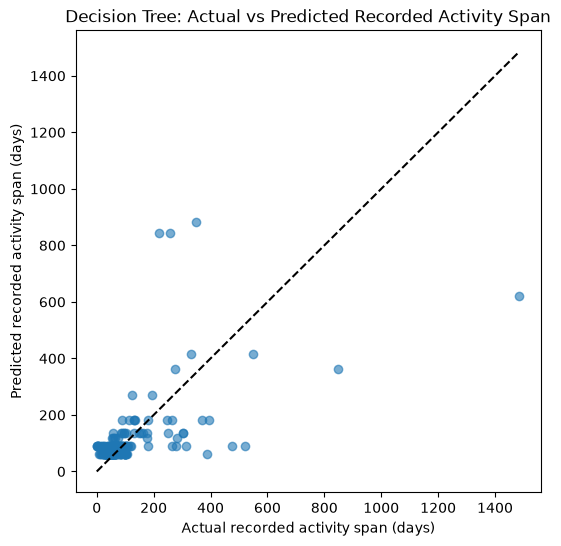

In [8]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([0, y_test.max()], [0, y_test.max()], linestyle="--", color="black")
plt.title("Decision Tree: Actual vs Predicted Recorded Activity Span")
plt.xlabel("Actual recorded activity span (days)")
plt.ylabel("Predicted recorded activity span (days)")
plt.show()

Because a tree gives the same prediction to every case in the same group, the predicted values form a few horizontal
"bands" instead of a smooth line.

## 9. Feature Importance

Feature importance shows which variables the tree used most when making its splits. It does **not** mean that a feature
*causes* longer or shorter cases.

In [9]:
importance = pd.DataFrame({
    "feature": X.columns,
    "importance": model.feature_importances_
})
importance

,feature,importance
0,events_per_case,0.697657
1,unique_activities,0.149111
2,unique_resources,0.153232


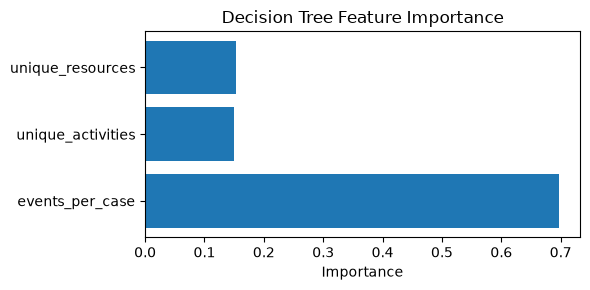

In [10]:
plt.figure(figsize=(6, 3))
plt.barh(importance["feature"], importance["importance"])
plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 10. Compare with the Baselines and Linear Regression

All approaches use the same 764 training cases and the same 192 test cases. Linear Regression is trained again here with
the same code as notebook 02, so no results are copied by hand. **Train R²** is shown next to test R² as a simple check
for overfitting.

In [11]:
linear_model = LinearRegression().fit(X_train, y_train)

mean_train = [y_train.mean()] * len(y_train)
median_train = [y_train.median()] * len(y_train)
approaches = [
    ("Mean baseline", mean_train, [y_train.mean()] * len(y_test)),
    ("Median baseline", median_train, [y_train.median()] * len(y_test)),
    ("Linear Regression", linear_model.predict(X_train), linear_model.predict(X_test)),
    ("Decision Tree", model.predict(X_train), y_pred),
]

**Compare all approaches on the same 192 test cases.** The loop calculates the same metrics for each approach; Train R² is shown next to Test R² as a simple check for overfitting.

In [12]:
# the same metrics for every approach, on the same 192 test cases
rows = []
for name, pred_train, pred_test in approaches:
    rows.append({
        "Model": name,
        "Test MAE": mean_absolute_error(y_test, pred_test),
        "Test RMSE": mean_squared_error(y_test, pred_test) ** 0.5,
        "Test R²": r2_score(y_test, pred_test),
        "Train R²": r2_score(y_train, pred_train),
    })
comparison = pd.DataFrame(rows).set_index("Model")
comparison.round(2)

,Test MAE,Test RMSE,Test R²,Train R²
Model,,,,
Mean baseline,71.98,147.26,-0.00,0.00
Median baseline,64.42,153.00,-0.08,-0.09
Linear Regression,59.01,126.02,0.26,0.18
Decision Tree,58.73,125.50,0.27,0.52


## 11. Train vs Test Check

Decision Trees can overfit: they learn the training data well but do worse on new cases. The table above shows a
**training R² of 0.52** but a **test R² of 0.27** for the tree, so the tree fits the training cases much better than new
cases. Linear Regression shows no such gap (0.18 vs 0.26).

## 12. Simple Conclusion

1. **Did the Decision Tree beat Linear Regression on MAE?** Only very slightly: 58.73 vs 59.01 days, a difference of
   less than half a day. Both are better than the median baseline (64.42 days) and the mean baseline (71.98 days).
2. **Did it improve RMSE?** Only very slightly: 125.50 vs 126.02 days. Large errors on long cases are still a problem.
3. **Did it improve R²?** Only very slightly: 0.27 vs 0.26. Both models explain only about a quarter of the variation.
4. **Did it avoid negative predictions?** Yes. No prediction is below zero; the lowest prediction is 62.82 days. But this
   also means that the tree predicts at least about 63 days even for very short cases.
5. **Is there evidence of overfitting?** Yes, some: training R² 0.52 vs test R² 0.27. The plot also shows a few cases that
   lasted about 200–350 days but were predicted at about 840–880 days, because they fell into a group learned from only a
   few very long training cases.
6. **Which feature was most important?** `events_per_case` (importance about 0.70). `unique_resources` and
   `unique_activities` were used much less (about 0.15 each). Importance shows what the tree used, not what causes long cases.

Overall, the Decision Tree gives almost the same result as Linear Regression. With these three features, changing the model
type changes the result very little, so better features will probably matter more than a more complex model.

**Next step:** Random Forest (notebook 04), which averages many trees and may give more stable predictions.